In [4]:
import pandas as pd


merged_df = pd.read_csv(r"C:\Users\haris\OneDrive\Desktop\PROJECT\final_merged_df.csv", sep = ",")

## Random Forest

In [2]:
top_20_genes_and_5_mut_and_2_cnv = [
    'CT62', 'KIF2C', 'GPR77', 'TTK', 'FSIP1', 'ZNF552', 'CEP55', 'XBP1',
    'GATA3', 'C6orf97', 'FOXA1', 'CDC20', 'THSD4', 'AGR3', 'CDCA8',
    'TBC1D9', 'MLPH', 'FOXC1', 'CENPA', 'ESR1', 'CDH1-m', 'GATA3-m', 'PIK3CA-m', 'TP53-m', 'TTN-m', "MYC_amp", "CCND1_amp"
]

X_selected = merged_df[top_20_genes_and_5_mut_and_2_cnv]
y_selected = merged_df['subtype']


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_selected, test_size=0.2, random_state=42, stratify=y_selected)



from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd


# model with balanced class weights
clf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_test)

# evaluate
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[34  0  0  0]
 [ 1 14  0  1]
 [ 0  0 90 10]
 [ 0  0 11 28]]

Classification Report:
               precision    recall  f1-score   support

  BRCA_Basal       0.97      1.00      0.99        34
   BRCA_Her2       1.00      0.88      0.93        16
   BRCA_LumA       0.89      0.90      0.90       100
   BRCA_LumB       0.72      0.72      0.72        39

    accuracy                           0.88       189
   macro avg       0.90      0.87      0.88       189
weighted avg       0.88      0.88      0.88       189



## Neural Network

In [ ]:
top_20_genes_and_5_mut_and_2_cnv = [
    'CT62', 'KIF2C', 'GPR77', 'TTK', 'FSIP1', 'ZNF552', 'CEP55', 'XBP1',
    'GATA3', 'C6orf97', 'FOXA1', 'CDC20', 'THSD4', 'AGR3', 'CDCA8',
    'TBC1D9', 'MLPH', 'FOXC1', 'CENPA', 'ESR1', 'CDH1-m', 'GATA3-m', 'PIK3CA-m', 'TP53-m', 'TTN-m', "MYC_amp", "CCND1_amp"
]

X_selected = merged_df[top_20_genes_and_5_mut_and_2_cnv]
y_selected = merged_df['subtype']

#### Log2 transform + Scaling is necessary for NN:

In [ ]:
top_20_genes_and_5_mut_and_2_cnv = [
    'CT62', 'KIF2C', 'GPR77', 'TTK', 'FSIP1', 'ZNF552', 'CEP55', 'XBP1',
    'GATA3', 'C6orf97', 'FOXA1', 'CDC20', 'THSD4', 'AGR3', 'CDCA8',
    'TBC1D9', 'MLPH', 'FOXC1', 'CENPA', 'ESR1', 'CDH1-m', 'GATA3-m', 'PIK3CA-m', 'TP53-m', 'TTN-m', "MYC_amp", "CCND1_amp"
]

X_selected = merged_df[top_20_genes_and_5_mut_and_2_cnv]
y_selected = merged_df['subtype']





from sklearn.preprocessing import StandardScaler
import numpy as np

# Identify binary columns (only 0 and 1 values)
binary_cols = [col for col in X_selected.columns if X_selected[col].nunique() == 2 and sorted(X_selected[col].unique()) == [0, 1]]

# Non-binary columns (gene expression etc.)
non_binary_cols = [col for col in X_selected.columns if col not in binary_cols]

# Log2 transform non-binary
X_log2 = X_selected.copy()
X_log2[non_binary_cols] = np.log2(X_log2[non_binary_cols] + 1)

# Scale non-binary
scaler = StandardScaler()
X_log2[non_binary_cols] = scaler.fit_transform(X_log2[non_binary_cols])





from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_log2, y_selected, test_size=0.2, random_state=42, stratify=y_selected)















from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight
import numpy as np


from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)


# Compute class weights
classes = np.unique(y_train_enc)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train_enc)
class_weights = dict(zip(classes, weights))

# Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(len(classes), activation='softmax')  # For multi-class
])

model.compile(optimizer=Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train

from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

model.fit(X_train, y_train_enc,
          validation_split=0.2,
          epochs=50,
          batch_size=32,
          class_weight=class_weights,
          callbacks=[early_stop])



Epoch 1/50


d:\Software\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4571 - loss: 1.3939 - val_accuracy: 0.6645 - val_loss: 0.9777
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7912 - loss: 0.7835 - val_accuracy: 0.7632 - val_loss: 0.7528
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8505 - loss: 0.5983 - val_accuracy: 0.8026 - val_loss: 0.6164
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8688 - loss: 0.4506 - val_accuracy: 0.8289 - val_loss: 0.5274
Epoch 5/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8736 - loss: 0.3545 - val_accuracy: 0.8224 - val_loss: 0.4798
Epoch 6/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8948 - loss: 0.2739 - val_accuracy: 0.8224 - val_loss: 0.4570
Epoch 7/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9212 - loss: 0.2336 - val_accuracy: 0.8224 - val_loss: 0.4508
Epoch 8/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8940 - loss: 0.2784 - val_accuracy: 0.8224 - val_loss: 0.4460
Epo

## Tuning the RF Model:

In [12]:
top_20_genes_and_5_mut_and_2_cnv = [
    'CT62', 'KIF2C', 'GPR77', 'TTK', 'FSIP1', 'ZNF552', 'CEP55', 'XBP1',
    'GATA3', 'C6orf97', 'FOXA1', 'CDC20', 'THSD4', 'AGR3', 'CDCA8',
    'TBC1D9', 'MLPH', 'FOXC1', 'CENPA', 'ESR1', 'CDH1-m', 'GATA3-m', 'PIK3CA-m', 'TP53-m', 'TTN-m', "MYC_amp", "CCND1_amp"
]

X_selected = merged_df[top_20_genes_and_5_mut_and_2_cnv]
y_selected = merged_df['subtype']


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_selected, test_size=0.2, random_state=42, stratify=y_selected)



In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint
import numpy as np

# parameter grid
param_dist = {
    'n_estimators': randint(100, 1000),
    'max_depth': randint(3, 30),
    'min_samples_split': randint(2, 10),
    'min_samples_leaf': randint(1, 10),
    'max_features': ['sqrt', 'log2', None],
    'class_weight': ['balanced', 'balanced_subsample']
}

rf = RandomForestClassifier(random_state=42)

#Random search
search = RandomizedSearchCV(
    rf,
    param_distributions=param_dist,
    n_iter=50,
    scoring='accuracy',
    cv=5,
    verbose=1,
    n_jobs=-1,
    random_state=42
)


In [13]:
search.fit(X_train, y_train)
best_model = search.best_estimator_
print("Best parameters:", search.best_params_)
print("Best CV score:", search.best_score_)

# Evaluate on test set
from sklearn.metrics import classification_report, confusion_matrix
y_pred = best_model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best parameters: {'class_weight': 'balanced', 'max_depth': 19, 'max_features': 'sqrt', 'min_samples_leaf': 4, 'min_samples_split': 7, 'n_estimators': 584}
Best CV score: 0.8941530149878008
[[34  0  0  0]
 [ 0 15  0  1]
 [ 0  1 87 12]
 [ 0  2  5 32]]
              precision    recall  f1-score   support

  BRCA_Basal       1.00      1.00      1.00        34
   BRCA_Her2       0.83      0.94      0.88        16
   BRCA_LumA       0.95      0.87      0.91       100
   BRCA_LumB       0.71      0.82      0.76        39

    accuracy                           0.89       189
   macro avg       0.87      0.91      0.89       189
weighted avg       0.90      0.89      0.89       189



accuracy went from 0.88 → 0.89, and recall for BRCA_LumB (your weakest class) improved from 0.72 to 0.82. Model is better balanced now without overfitting. No need for more feature engineering or adding genes. Next : save the model

In [14]:
import joblib

# Save model
joblib.dump(best_model, 'rf_model.pkl')

['rf_model.pkl']

In [15]:
merged_df

,patient_id_x,UBE2Q2P2,HMGB1P1,RNU12-2P,SSX9P,EZHIP,EFCAB8,SRP14P1,TRIM75P,SPATA31B1P,...,ZZEF1,ZZZ3,subtype,CDH1-m,GATA3-m,PIK3CA-m,TP53-m,TTN-m,MYC_amp,CCND1_amp
0,TCGA-3C-AAAU-01,12.9316,52.1503,0.0000,0.0000,1.7233,0.3447,4.1359,0.6893,0.0,...,1894.930,1180.460,BRCA_LumA,0.0,1.0,0.0,0.0,0.0,0,1
1,TCGA-3C-AALI-01,17.3790,69.7553,1.0875,0.5438,144.1000,4.8940,1.6313,0.5438,0.0,...,1318.650,406.743,BRCA_Her2,0.0,0.0,0.0,1.0,1.0,0,0
2,TCGA-3C-AALJ-01,9.2294,154.2970,0.0000,0.0000,0.0000,2.7199,2.7199,0.0000,0.0,...,942.883,509.519,BRCA_LumB,0.0,1.0,0.0,0.0,1.0,1,0
3,TCGA-3C-AALK-01,11.0799,143.8640,0.4137,0.0000,0.0000,2.0687,4.5511,0.0000,0.0,...,781.134,700.869,BRCA_LumA,0.0,0.0,1.0,0.0,0.0,0,0
4,TCGA-4H-AAAK-01,14.4298,84.2128,0.4255,0.0000,0.4255,2.9787,2.9787,0.0000,0.0,...,831.915,881.702,BRCA_LumA,1.0,0.0,0.0,0.0,0.0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
940,TCGA-WT-AB44-01,3.2580,42.2643,4.0725,0.0000,0.8145,3.2580,4.0725,0.0000,0.0,...,800.652,443.087,BRCA_LumA,1.0,0.0,0.0,0.0,0.0,0,0
941,TCGA-XX-A899-01,21.4409,137.7760,2.7559,0.0000,2.7559,1.5748,6.6929,0.0000,0.0,...,1933.860,670.079,BRCA_LumA,1.0,0.0,1.0,0.0,0.0,0,1
942,TCGA-XX-A89A-01,27.2744,64.1427,0.4724,0.0000,17.4776,1.4171,6.6131,0.0000,0.0,...,1437.410,953.708,BRCA_LumA,1.0,0.0,1.0,0.0,0.0,0,1
943,TCGA-Z7-A8R5-01,7.2933,85.0461,0.5973,0.0000,0.0000,0.5973,4.1812,0.0000,0.0,...,754.413,750.829,BRCA_LumA,1.0,0.0,1.0,0.0,0.0,0,0


## Testing 

In [17]:
XY = pd.concat([X_selected, y_selected], axis=1)


In [43]:
XY

,UBE2T,BIRC5,NUF2,CDC6,CCNB1,TYMS,MYBL2,CEP55,MELK,NDC80,RRM2,UBE2C,CENPF,PTTG1,EXO1,ORC6L,ANLN,CCNE1,CDC20,MKI67,KIF2C,ACTR3B,MYC,EGFR,KRT5,PHGDH,CDH3,MIA,KRT17,FOXC1,SFRP1,KRT14,ESR1,SLC39A6,BAG1,MAPT,PGR,CXXC5,MLPH,BCL2,MDM2,NAT1,FOXA1,BLVRA,MMP11,GPR160,FGFR4,GRB7,TMEM45B,ERBB2,CDH1-m,GATA3-m,PIK3CA-m,TP53-m,TTN-m,MYC_amp,CCND1_amp,subtype
0,318.4650,390.7980,295.0280,488.0370,1282.820,493.1140,749.9780,319.8430,264.3530,353.9650,1477.2100,555.5900,1824.970,383.6050,198.5240,206.1060,828.2150,163.3680,603.1530,2582.8700,656.2300,359.824,2223.740,53.0775,1.3786,741.361,129.592,5.8006,0.6893,19.6456,473.2170,0.0000,3457.9600,90765.90,1890.570,7988.160,2273.2700,1855.300,6067.03,2315.760,14938.200,8014.700,5448.37,850.618,11505.40,1347.620,67.8978,807.880,2.4126,7113.41,0.0,1.0,0.0,0.0,0.0,0,1,BRCA_LumA
1,1004.3500,859.4940,494.2900,553.0180,1877.650,719.3200,4292.5500,572.5940,487.7650,293.6380,3219.1400,1351.2800,2230.560,553.0180,493.2030,475.2580,1566.0700,227.8410,648.7220,2285.4800,830.8860,144.644,176.726,73.9532,394.7800,759.652,812.942,8.4611,616.0960,52.2023,101.6860,312.6700,68.5155,1699.29,728.026,190.321,27.1887,982.599,17575.30,264.818,922.240,571.506,6049.48,1873.300,9584.56,3778.140,2193.5800,26621.600,799.3470,194625.00,0.0,0.0,0.0,1.0,1.0,0,0,BRCA_Her2
2,757.0260,744.4610,472.3480,925.6570,1822.300,667.0170,2933.8200,325.4760,546.6910,484.1340,1305.5300,1195.8300,1598.370,802.3570,159.5650,368.0870,637.3530,178.6040,873.9800,949.2290,728.0140,153.219,1214.870,45.3309,2.7199,106.981,329.102,1.9583,7.2529,159.5650,67.0898,2.7199,7482.3200,15816.90,1869.720,2932.000,473.8350,2165.910,5097.01,2538.530,1794.200,1205.800,4620.13,2153.220,14854.90,535.811,33.5449,1256.570,5.4397,11070.70,0.0,1.0,0.0,0.0,1.0,1,0,BRCA_LumB
3,373.1900,522.0190,158.8750,183.2850,827.058,724.6920,503.5170,290.8560,245.7590,183.6990,909.3920,496.8970,1614.400,311.9570,120.8110,64.1291,631.7750,44.2698,539.0980,1139.4300,301.6140,135.292,1405.880,254.0260,3429.4600,694.663,1001.240,158.2500,5433.6000,266.4460,1236.6600,4697.5600,2485.3100,19032.70,1651.160,2402.150,2236.4600,1822.510,10655.40,2172.110,1591.230,1152.670,7352.09,1327.270,8525.44,662.391,163.8390,1992.550,532.4780,36022.80,0.0,0.0,1.0,0.0,0.0,0,0,BRCA_LumA
4,192.3400,202.9620,122.5530,399.5750,647.660,675.7230,481.7020,207.2340,245.5320,177.8720,384.2550,322.1280,1109.360,257.8720,84.6809,60.4255,359.5750,56.5957,389.3620,1206.3800,331.4890,235.319,4137.450,164.2510,2734.4700,626.383,590.638,131.2300,2997.8700,150.2130,1531.9100,2896.6000,5518.3000,3834.89,2154.500,7789.360,4425.1900,703.404,6126.81,1575.320,1226.380,130.638,6799.57,651.064,32954.00,744.681,781.2770,1039.570,385.1060,12236.60,1.0,0.0,0.0,0.0,0.0,1,0,BRCA_LumA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
940,96.1108,55.4103,35.8379,23.6204,185.706,79.2751,32.5799,26.0639,13.0320,27.6929,21.1769,54.5714,214.213,79.8208,14.6610,19.5480,65.1598,17.9190,42.3539,74.9338,13.0320,312.767,1649.360,48.0554,853.5940,419.466,928.528,43.9829,1070.2500,341.2750,404.8050,1036.8600,4558.7500,1690.90,2285.030,1450.620,195.4800,172.674,38253.70,161.271,1246.180,3679.900,6139.69,2054.980,9205.46,1384.650,937.4870,354.307,447.1590,9404.19,1.0,0.0,0.0,0.0,0.0,0,0,BRCA_LumA
941,183.0710,165.1730,103.9370,184.2520,553.937,512.0390,280.3150,218.1100,97.2441,121.6530,211.0240,266.1420,1248.030,251.1810,100.0000,49.2126,724.4090,40.1575,314.9610,1198.0300,250.7870,175.197,3964.170,414.1690,1374.4100,458.661,490.158,13.1693,3163.3900,168.8980,1733.8600,1151.9700,2731.5000,5103.94,1561.310,781.496,11565.9000,850.787,8582.68,1139.370,3292.130,236.614,4100.39,968.898,7656.30,800.000,340.9450,953.150,285.8270,8563.78,1.0,0.0,1.0,0.0,0.0,0,1,BRCA_LumA
942,163.9110,151.1150,103.9210,136.0420,620.690,280.6750,437.8840,240.4350,218.2330,106.7550,324.9880,

In [44]:
print(XY.iloc[2])


UBE2T          757.026
BIRC5          744.461
NUF2           472.348
CDC6           925.657
CCNB1           1822.3
TYMS           667.017
MYBL2          2933.82
CEP55          325.476
MELK           546.691
NDC80          484.134
RRM2           1305.53
UBE2C          1195.83
CENPF          1598.37
PTTG1          802.357
EXO1           159.565
ORC6L          368.087
ANLN           637.353
CCNE1          178.604
CDC20           873.98
MKI67          949.229
KIF2C          728.014
ACTR3B         153.219
MYC            1214.87
EGFR           45.3309
KRT5            2.7199
PHGDH          106.981
CDH3           329.102
MIA             1.9583
KRT17           7.2529
FOXC1          159.565
SFRP1          67.0898
KRT14           2.7199
ESR1           7482.32
SLC39A6        15816.9
BAG1           1869.72
MAPT            2932.0
PGR            473.835
CXXC5          2165.91
MLPH           5097.01
BCL2           2538.53
MDM2            1794.2
NAT1            1205.8
FOXA1          4620.13
BLVRA      

In [19]:
print(XY.iloc[27])


CT62           117.149
KIF2C          659.638
GPR77          14.4183
TTK             196.45
FSIP1           1609.8
ZNF552         3053.44
CEP55          604.127
XBP1           44690.6
GATA3          10663.8
C6orf97        23.0693
FOXA1          10212.5
CDC20          655.673
THSD4          1437.15
AGR3           2337.57
CDCA8          515.455
TBC1D9         1815.99
MLPH           14805.8
FOXC1          114.986
CENPA          144.904
ESR1           1301.25
CDH1-m             0.0
GATA3-m            0.0
PIK3CA-m           0.0
TP53-m             0.0
TTN-m              0.0
MYC_amp              0
CCND1_amp            0
subtype      BRCA_Her2
Name: 27, dtype: object


In [20]:
print(XY.iloc[676])


CT62             0.6158
KIF2C           950.739
GPR77           13.2389
TTK             352.832
FSIP1            1.5394
ZNF552          176.108
CEP55           574.507
XBP1            6772.78
GATA3           536.638
C6orf97         57.5739
FOXA1           49.2611
CDC20           748.153
THSD4            405.48
AGR3            47.1059
CDCA8           749.076
TBC1D9          1417.18
MLPH            577.894
FOXC1           685.653
CENPA           248.768
ESR1             201.97
CDH1-m              0.0
GATA3-m             0.0
PIK3CA-m            0.0
TP53-m              1.0
TTN-m               1.0
MYC_amp               1
CCND1_amp             0
subtype      BRCA_Basal
Name: 676, dtype: object


# XGBOOST CLASSIFIER:

In [21]:
top_20_genes_and_5_mut_and_2_cnv = [
    'CT62', 'KIF2C', 'GPR77', 'TTK', 'FSIP1', 'ZNF552', 'CEP55', 'XBP1',
    'GATA3', 'C6orf97', 'FOXA1', 'CDC20', 'THSD4', 'AGR3', 'CDCA8',
    'TBC1D9', 'MLPH', 'FOXC1', 'CENPA', 'ESR1', 'CDH1-m', 'GATA3-m', 'PIK3CA-m', 'TP53-m', 'TTN-m', "MYC_amp", "CCND1_amp"
]

X_selected = merged_df[top_20_genes_and_5_mut_and_2_cnv]
y_selected = merged_df['subtype']
le = LabelEncoder()
y_enc = le.fit_transform(y_selected)

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_enc, test_size=0.2, random_state=42, stratify=y_selected)



from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd


# model with balanced class weights
clf = XGBClassifier( class_weight='balanced')
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_test)

# evaluate
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[34  0  0  0]
 [ 1 13  1  1]
 [ 0  0 90 10]
 [ 0  0  9 30]]

Classification Report:
               precision    recall  f1-score   support

           0       0.97      1.00      0.99        34
           1       1.00      0.81      0.90        16
           2       0.90      0.90      0.90       100
           3       0.73      0.77      0.75        39

    accuracy                           0.88       189
   macro avg       0.90      0.87      0.88       189
weighted avg       0.89      0.88      0.88       189



d:\Software\anaconda3\Lib\site-packages\xgboost\training.py:183: UserWarning: [19:01:12] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "class_weight" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [2]:
genes = [
    "UBE2T", "BIRC5", "NUF2", "CDC6", "CCNB1", "TYMS", "MYBL2", "CEP55", "MELK", "NDC80",
    "RRM2", "UBE2C", "CENPF", "PTTG1", "EXO1", "ORC6L", "ANLN", "CCNE1", "CDC20", "MKI67",
    "KIF2C", "ACTR3B", "MYC", "EGFR", "KRT5", "PHGDH", "CDH3", "MIA", "KRT17", "FOXC1",
    "SFRP1", "KRT14", "ESR1", "SLC39A6", "BAG1", "MAPT", "PGR", "CXXC5", "MLPH", "BCL2",
    "MDM2", "NAT1", "FOXA1", "BLVRA", "MMP11", "GPR160", "FGFR4", "GRB7", "TMEM45B", "ERBB2"
]

In [1]:
top_20_genes_and_5_mut_and_2_cnv = [
    'CT62', 'KIF2C', 'GPR77', 'TTK', 'FSIP1', 'ZNF552', 'CEP55', 'XBP1',
    'GATA3', 'C6orf97', 'FOXA1', 'CDC20', 'THSD4', 'AGR3', 'CDCA8',
    'TBC1D9', 'MLPH', 'FOXC1', 'CENPA', 'ESR1'
]

In [3]:
present_genes = list(set(genes) & set(top_20_genes_and_5_mut_and_2_cnv))
print("Common genes:", present_genes)

Common genes: ['FOXC1', 'CDC20', 'CEP55', 'KIF2C', 'MLPH', 'ESR1', 'FOXA1']


# RF with PAM50 Genes: 

In [ ]:

pam50_genes = [
    "UBE2T", "BIRC5", "NUF2", "CDC6", "CCNB1", "TYMS", "MYBL2", "CEP55", "MELK", "NDC80",
    "RRM2", "UBE2C", "CENPF", "PTTG1", "EXO1", "ORC6L", "ANLN", "CCNE1", "CDC20", "MKI67",
    "KIF2C", "ACTR3B", "MYC", "EGFR", "KRT5", "PHGDH", "CDH3", "MIA", "KRT17", "FOXC1",
    "SFRP1", "KRT14", "ESR1", "SLC39A6", "BAG1", "MAPT", "PGR", "CXXC5", "MLPH", "BCL2",
    "MDM2", "NAT1", "FOXA1", "BLVRA", "MMP11", "GPR160", "FGFR4", "GRB7", "TMEM45B", "ERBB2", 'CDH1-m', 'GATA3-m', 'PIK3CA-m', 'TP53-m', 'TTN-m', "MYC_amp", "CCND1_amp"
]

#Common_genes = ['FOXC1', 'CDC20', 'CEP55', 'KIF2C', 'MLPH', 'ESR1', 'FOXA1']

X_selected = merged_df[pam50_genes]
y_selected = merged_df['subtype']


from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_selected, y_selected, test_size=0.2, random_state=42, stratify=y_selected)



from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd


# model with balanced class weights
clf = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
clf.fit(X_train, y_train)

# predict
y_pred = clf.predict(X_test)

# evaluate
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Confusion Matrix:
 [[34  0  0  0]
 [ 0 15  1  0]
 [ 0  1 98  1]
 [ 0  0  9 30]]

Classification Report:
               precision    recall  f1-score   support

  BRCA_Basal       1.00      1.00      1.00        34
   BRCA_Her2       0.94      0.94      0.94        16
   BRCA_LumA       0.91      0.98      0.94       100
   BRCA_LumB       0.97      0.77      0.86        39

    accuracy                           0.94       189
   macro avg       0.95      0.92      0.93       189
weighted avg       0.94      0.94      0.93       189



# Neural Network with PAM50:

In [21]:
pam50_genes = [
    "UBE2T", "BIRC5", "NUF2", "CDC6", "CCNB1", "TYMS", "MYBL2", "CEP55", "MELK", "NDC80",
    "RRM2", "UBE2C", "CENPF", "PTTG1", "EXO1", "ORC6L", "ANLN", "CCNE1", "CDC20", "MKI67",
    "KIF2C", "ACTR3B", "MYC", "EGFR", "KRT5", "PHGDH", "CDH3", "MIA", "KRT17", "FOXC1",
    "SFRP1", "KRT14", "ESR1", "SLC39A6", "BAG1", "MAPT", "PGR", "CXXC5", "MLPH", "BCL2",
    "MDM2", "NAT1", "FOXA1", "BLVRA", "MMP11", "GPR160", "FGFR4", "GRB7", "TMEM45B", "ERBB2", 'CDH1-m', 'GATA3-m', 'PIK3CA-m', 'TP53-m', 'TTN-m', "MYC_amp", "CCND1_amp"
]

X_selected = merged_df[pam50_genes]
y_selected = merged_df['subtype']


X_selected = X_selected[:-2]
y_selected = y_selected[:-2]

from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
y_enc = le.fit_transform(y_selected)


from sklearn.preprocessing import StandardScaler
import numpy as np

# Identify binary columns (only 0 and 1 values)
binary_cols = [col for col in X_selected.columns if X_selected[col].nunique() == 2 and sorted(X_selected[col].unique()) == [0, 1]]

# Non-binary columns (gene expression etc.)
non_binary_cols = [col for col in X_selected.columns if col not in binary_cols]

# Log2 transform non-binary
X_log2 = X_selected.copy()
X_log2[non_binary_cols] = np.log2(X_log2[non_binary_cols] + 1)

# Scale non-binary
scaler = StandardScaler()
X_log2[non_binary_cols] = scaler.fit_transform(X_log2[non_binary_cols])





from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X_log2, y_enc, test_size=0.2, random_state=42, stratify=y_selected)






from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.optimizers import Adam
from sklearn.utils.class_weight import compute_class_weight
import numpy as np






# Compute class weights
classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
class_weights = dict(zip(classes, weights))

# Build model
model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train.shape[1],)),
    Dense(32, activation='relu'),
    Dense(len(classes), activation='softmax')  # For multi-class
])

model.compile(optimizer=Adam(1e-3), loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train

from keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

model.fit(X_train, y_train,
          validation_split=0.2,
          epochs=50,
          batch_size=32,
          class_weight=class_weights,
          callbacks=[early_stop])


Epoch 1/50


d:\Software\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3215 - loss: 1.3125 - val_accuracy: 0.7748 - val_loss: 0.8207
Epoch 2/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.7964 - loss: 0.7150 - val_accuracy: 0.8874 - val_loss: 0.4903
Epoch 3/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8764 - loss: 0.4023 - val_accuracy: 0.9007 - val_loss: 0.3446
Epoch 4/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.8988 - loss: 0.2879 - val_accuracy: 0.9205 - val_loss: 0.2734
Epoch 5/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9156 - loss: 0.2045 - val_accuracy: 0.9139 - val_loss: 0.2358
Epoch 6/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9095 - loss: 0.2032 - val_accuracy: 0.9205 - val_loss: 0.2047
Epoch 7/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9446 - loss: 0.1441 - val_accuracy: 0.9205 - val_loss: 0.1902
Epoch 8/50
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9548 - loss: 0.1270 - val_accuracy: 0.9205 - val_loss: 0.1825
Epo

In [23]:
import numpy as np
from tensorflow.keras.models import load_model

# Load model and any preprocessing objects
#model = load_model("my_model.h5")
selected_genes = ["UBE2T", "BIRC5", "NUF2", "CDC6", "CCNB1", "TYMS", "MYBL2", "CEP55", "MELK", "NDC80",
    "RRM2", "UBE2C", "CENPF", "PTTG1", "EXO1", "ORC6L", "ANLN", "CCNE1", "CDC20", "MKI67",
    "KIF2C", "ACTR3B", "MYC", "EGFR", "KRT5", "PHGDH", "CDH3", "MIA", "KRT17", "FOXC1",
    "SFRP1", "KRT14", "ESR1", "SLC39A6", "BAG1", "MAPT", "PGR", "CXXC5", "MLPH", "BCL2",
    "MDM2", "NAT1", "FOXA1", "BLVRA", "MMP11", "GPR160", "FGFR4", "GRB7", "TMEM45B", "ERBB2", 'CDH1-m', 'GATA3-m', 'PIK3CA-m', 'TP53-m', 'TTN-m', "MYC_amp", "CCND1_amp"]  # same genes used in training, in order

def predict_subtype(sample_dict):
    # sample_dict: dict of {gene_name: expression_value}
    x_input = np.array([[sample_dict[gene] for gene in selected_genes]])
    pred = model.predict(x_input)
    subtype = np.argmax(pred, axis=1)[0]
    return subtype, pred[0]  # return class and probabilities

In [42]:
sample = {
     "UBE2T": 168.444,
    "BIRC5": 123.036,
    "NUF2": 36.4364,
    "CDC6": 86.6111,
    "CCNB1": 307.619,
    "TYMS": 268.226,
    "MYBL2": 172.028,
    "CEP55": 80.6379,
    "MELK": 38.8257,
    "NDC80": 71.6782,
    "RRM2": 179.793,
    "UBE2C": 136.786,
    "CENPF": 222.202,
    "PTTG1": 210.256,
    "EXO1": 45.9935,
    "ORC6L": 38.8257,
    "ANLN": 77.6513,
    "CCNE1": 44.7989,
    "CDC20": 169.041,
    "MKI67": 244.9,
    "KIF2C": 58.5372,
    "ACTR3B": 230.565,
    "MYC": 1834.96,
    "EGFR": 94.9736,
    "KRT5": 15913.1,
    "PHGDH": 2661.05,
    "CDH3": 3679.48,
    "MIA": 2854.25,
    "KRT17": 17675.8,
    "FOXC1": 757.997,
    "SFRP1": 13191.2,
    "KRT14": 37671.1,
    "ESR1": 3301.38,
    "SLC39A6": 7637.31,
    "BAG1": 2589.42,
    "MAPT": 1440.13,
    "PGR": 439.029,
    "CXXC5": 586.566,
    "MLPH": 5882.39,
    "BCL2": 815.339,
    "MDM2": 1119.97,
    "NAT1": 3042.74,
    "FOXA1": 2987.78,
    "BLVRA": 1845.71,
    "MMP11": 2920.89,
    "GPR160": 393.633,
    "FGFR4": 184.571,
    "GRB7": 1126.54,
    "TMEM45B": 231.759,
    "ERBB2": 8288.39,
    "CDH1-m": 1.0,
    "GATA3-m": 0.0,
    "PIK3CA-m": 1.0,
    "TP53-m": 0.0,
    "TTN-m": 0.0,
    "MYC_amp": 0,
    "CCND1_amp": 0
}
subtype, probs = predict_subtype(sample)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step


In [40]:
print(probs)


[0. 0. 1. 0.]


In [41]:

from sklearn.preprocessing import LabelEncoder

# Assuming you saved the encoder as `le`
# And you have predicted label as integer:
predicted_label = 2  # e.g., 2
original_label = le.inverse_transform([predicted_label])[0]
print(original_label)

BRCA_LumA


In [34]:
import numpy as np

# Example one-hot prediction
one_hot = np.array([0., 0., 1., 0.])

# Get index of the highest value (predicted class)
pred_index = np.argmax(one_hot)

# Recover label using your LabelEncoder
original_label = le.inverse_transform([pred_index])[0]
print(original_label)

BRCA_LumA


In [18]:
X_val = XY[-2:]


In [27]:
print(X_val.iloc[1])


UBE2T          773.902
BIRC5          794.317
NUF2           695.607
CDC6           764.506
CCNB1          2815.14
TYMS            1439.4
MYBL2          3404.26
CEP55          809.743
MELK           898.826
NDC80          491.344
RRM2            1006.0
UBE2C          1796.96
CENPF          3304.05
PTTG1          965.637
EXO1           394.606
ORC6L          174.685
ANLN           981.644
CCNE1          51.5007
CDC20          2179.73
MKI67          3179.12
KIF2C          1180.69
ACTR3B         222.706
MYC            2756.33
EGFR           32.0139
KRT5           968.073
PHGDH          2294.21
CDH3           709.178
MIA            48.6264
KRT17          1304.57
FOXC1          38.2775
SFRP1           457.59
KRT14          1249.59
ESR1           6429.93
SLC39A6        11316.9
BAG1           1467.26
MAPT           8327.45
PGR            2240.39
CXXC5          3177.03
MLPH           7300.22
BCL2           882.819
MDM2           835.842
NAT1           2122.66
FOXA1          8061.24
BLVRA      

In [37]:
print(X_val.iloc[0])


UBE2T          168.444
BIRC5          123.036
NUF2           36.4364
CDC6           86.6111
CCNB1          307.619
TYMS           268.226
MYBL2          172.028
CEP55          80.6379
MELK           38.8257
NDC80          71.6782
RRM2           179.793
UBE2C          136.786
CENPF          222.202
PTTG1          210.256
EXO1           45.9935
ORC6L          38.8257
ANLN           77.6513
CCNE1          44.7989
CDC20          169.041
MKI67            244.9
KIF2C          58.5372
ACTR3B         230.565
MYC            1834.96
EGFR           94.9736
KRT5           15913.1
PHGDH          2661.05
CDH3           3679.48
MIA            2854.25
KRT17          17675.8
FOXC1          757.997
SFRP1          13191.2
KRT14          37671.1
ESR1           3301.38
SLC39A6        7637.31
BAG1           2589.42
MAPT           1440.13
PGR            439.029
CXXC5          586.566
MLPH           5882.39
BCL2           815.339
MDM2           1119.97
NAT1           3042.74
FOXA1          2987.78
BLVRA      

In [12]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Assuming X_val and y_val are your validation features and labels
y_pred_proba = model.predict(X_test)
y_test_bin = label_binarize(y_test, classes=[0, 1, 2, 3])  # for 4 subtypes

n_classes = y_test_bin.shape[1]

6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step 


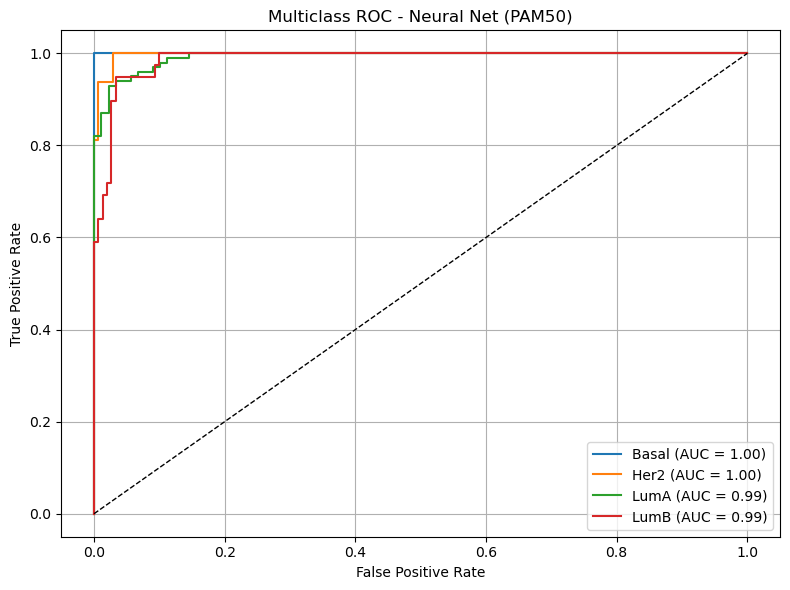

In [13]:
fpr = {}
tpr = {}
roc_auc = {}

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_pred_proba[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot
plt.figure(figsize=(8, 6))
for i, label in enumerate(["Basal", "Her2", "LumA", "LumB"]):
    plt.plot(fpr[i], tpr[i], label=f"{label} (AUC = {roc_auc[i]:.2f})")

plt.plot([0, 1], [0, 1], "k--", lw=1)
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Multiclass ROC - Neural Net (PAM50)")
plt.legend(loc="lower right")
plt.grid()
plt.tight_layout()
plt.show()